# Imports

In [2]:
import torchvision.datasets as dsets
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
from torchvision.datasets import samplers
from pytorch_metric_learning import samplers

import matplotlib.pyplot as plt


# Transforms


In [3]:
trainingTransform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    ])

# Datasets

In [4]:
trainingDataset = dsets.ImageFolder(
    root='C:/Users/Robyn/Desktop/Research Project/imgs/Train',
    transform=trainingTransform
)
trainingDatasetTotalClasses = len(trainingDataset.classes)
trainingDatasetTotalImages = len(trainingDataset)
print( trainingDatasetTotalClasses, " Total Classes")
print(trainingDatasetTotalImages, "Total Images")




87  Total Classes
286 Total Images


# Sampler

In [5]:
labels = trainingDataset.targets
mPerClass = 2

tripletSampler = samplers.MPerClassSampler(labels, mPerClass)

# Dataloaders


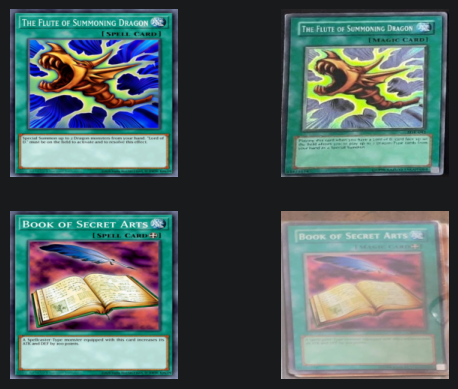

In [9]:
batchSize = 32
trainingDataLoader = DataLoader(
    trainingDataset,
    batchSize,
    sampler = tripletSampler)

trainFeatures, trainLabels = next(iter(trainingDataLoader))
img = trainFeatures[0].squeeze()
imgTwo = trainFeatures[1].squeeze()
imgThree = trainFeatures[2].squeeze()
imgFour = trainFeatures[3].squeeze()

plt.subplot(2,2,1)
plt.imshow(img.permute(1,2,0))
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(imgTwo.permute(1,2,0))
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(imgThree.permute(1,2,0))
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(imgFour.permute(1,2,0))
plt.axis('off')

plt.show()

# Image Embeddings